# Student Dropout Project

## Setup
### 1. Choose what to run

For your first test, leave these values unchanged.

| Setting | Meaning |
| --- | --- |
| `RUN_TABICL = True` | Fit the real model and compare all 544 validation outcomes. |
| `AUDIT_MODE = "preview"` | Show existing progress; do not compute explanation cases. |
| `AUDIT_MODE = "one_case"` | Compute one **new** complete case, then stop. This is a test, not the full audit. |
| `AUDIT_MODE = "full"` | Resume **all remaining validation cases**, with no case cap. This can take many hours. |
| `REPORT_MODE = "auto"` | Generate a full report only when all 544 case records are ready. |
| `REPORT_MODE = "partial"` | Request an explicitly incomplete report from available cases. |

If packages are missing, set `INSTALL_DEPENDENCIES = True`, run the installation cell, restart the kernel, then set it back to `False` and run again. A checkpoint is the pretrained model file; leave its path empty to use the verified local cache or download it automatically.

In [1]:
PROJECT_FOLDER = ""            # Usually leave empty; auto-detect the code folder.
INSTALL_DEPENDENCIES = False
RUN_TABICL = True
AUDIT_MODE = "preview"          # "preview", "one_case", or "full"
REPORT_MODE = "auto"            # "auto", "partial", or "none"
CHECKPOINT_FILE = ""            # Optional existing .ckpt file; never a password/key.
SHOW_SAVED_CASE = False         # Case-level explanation tables: keep outputs private.
RUN_STUDENT_SCENARIOS = False   # Optional real-model what-if table, after TabICL.
STUDENT_INDEX = 0               # Validation position, from 0 to 543; never a test ID.

if AUDIT_MODE not in {"preview", "one_case", "full"}:
    raise ValueError('Choose AUDIT_MODE="preview", "one_case", or "full".')
if REPORT_MODE not in {"auto", "partial", "none"}:
    raise ValueError('Choose REPORT_MODE="auto", "partial", or "none".')

### 2. Locate the project and check your Python
This cell works from the repository root, the Notebook Kit, or the code folder. If auto-detection fails, paste the folder containing `src`, `requirements.txt`, and `W1_Noey_Enhanced` into `PROJECT_FOLDER` above.

In [2]:
from pathlib import Path
import sys, os, json, hashlib, subprocess, time

if sys.version_info[:2] != (3, 12):
    raise RuntimeError(
        f"This project requires Python 3.12; the current kernel is {sys.version.split()[0]}. "
        "Select the Python 3.12/.venv-core kernel, restart it, and run from the top."
    )

def find_code_root(override=""):
    if override:
        candidates = [Path(override).expanduser()]
    else:
        candidates = []
        for base in [Path.cwd(), *list(Path.cwd().parents)[:4]]:
            candidates.extend([
                base,
                base / "Student Dropout Project" / "Code" / "Student-Dropout-Risk",
                base / "Code" / "Student-Dropout-Risk",
            ])
    for candidate in candidates:
        root = candidate.resolve()
        if all((root / marker).is_file() for marker in (
            "requirements.txt", "src/modeling.py",
            "W1_Noey_Enhanced/scripts/run_enhanced_audit.py",
        )):
            return root
    raise FileNotFoundError(
        "Cannot find the code folder. Extract the Notebook Kit first, or set "
        "PROJECT_FOLDER to your Student-Dropout-Risk folder and rerun this cell."
    )

CODE_ROOT = find_code_root(PROJECT_FOLDER)
AUDIT_ROOT = CODE_ROOT / "W1_Noey_Enhanced"
OUTPUTS = AUDIT_ROOT / "outputs"
NOTEBOOK_OUTPUT = OUTPUTS / "notebook"
NOTEBOOK_OUTPUT.mkdir(parents=True, exist_ok=True)
CACHE_ROOT = Path("/workspace/.cache") if Path("/workspace/.cache").is_dir() else NOTEBOOK_OUTPUT / ".cache"
for name, value in {
    "HF_HOME": CACHE_ROOT / "huggingface",
    "XDG_CACHE_HOME": CACHE_ROOT,
    "MPLCONFIGDIR": CACHE_ROOT / "matplotlib",
}.items():
    Path(value).mkdir(parents=True, exist_ok=True)
    os.environ.setdefault(name, str(value))
# Match the recorded CPU run. Set these before importing numerical/model packages.
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"
print("Python kernel:", sys.executable)
print("Code folder:", CODE_ROOT)
print("Notebook-generated outputs:", NOTEBOOK_OUTPUT)

Python kernel: c:\Users\NOEYnoey\AppData\Local\Programs\Python\Python312\python.exe
Code folder: C:\Users\NOEYnoey\OneDrive\AIT\Student_Dropout_Notebook_Kit\Student Dropout Project\Code\Student-Dropout-Risk
Notebook-generated outputs: C:\Users\NOEYnoey\OneDrive\AIT\Student_Dropout_Notebook_Kit\Student Dropout Project\Code\Student-Dropout-Risk\W1_Noey_Enhanced\outputs\notebook


### 3. Check or install dependencies
This uses the project's exact `requirements.txt`; it does not upgrade packages to unrelated versions. Installation may download large packages. If you use the prepared environment, this cell should report that the pinned packages are already installed.

In [3]:
from importlib.metadata import version, PackageNotFoundError
from packaging.requirements import Requirement

requirements = []
for line in (CODE_ROOT / "requirements.txt").read_text().splitlines():
    item = line.split("#", 1)[0].strip()
    if item:
        requirements.append(Requirement(item))

dependency_rows = []
for requirement in requirements:
    try:
        installed = version(requirement.name)
        matches = requirement.specifier.contains(installed, prereleases=True)
    except PackageNotFoundError:
        installed, matches = "missing", False
    dependency_rows.append((requirement.name, str(requirement.specifier), installed, matches))

missing_or_mismatched = [row for row in dependency_rows if not row[3]]
if INSTALL_DEPENDENCIES:
    # The protocol uses CPU. Install the official CPU wheel first to avoid a large CUDA runtime.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--index-url",
                           "https://download.pytorch.org/whl/cpu", "torch==2.14.0"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", str(CODE_ROOT / "requirements.txt")])
    subprocess.check_call([sys.executable, "-m", "pip", "check"])
    raise RuntimeError("Installation finished. Restart the kernel, set INSTALL_DEPENDENCIES=False, and run from the top.")

print(f"All {len(requirements)} project dependency pins match this kernel.")

All 15 project dependency pins match this kernel.


### 4. Load helpers and check required input files
The three original files below must be present. Do not regenerate split IDs or replace the final-test lock. A fresh code-only GitHub clone needs your authorized original files in the displayed locations. The Notebook Kit includes the required local input snapshot.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image

sys.path[:0] = [str(CODE_ROOT), str(AUDIT_ROOT / "scripts")]
import run_enhanced_audit as audit
import actual_data_audit as actual
from development_population import load_population
from validation_descriptive_audit import observed_groups

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "figure.facecolor": "white",
})
INPUT_FILES = [CODE_ROOT / name for name in (
    "eda_uci_data/data/dropout_data.csv", "artifacts/split_ids.csv", "artifacts/final_test.lock",
)]
display(pd.DataFrame({"Required file": [str(p) for p in INPUT_FILES], "Present": [p.is_file() for p in INPUT_FILES]}))
missing_inputs = [str(p) for p in INPUT_FILES if not p.is_file()]
if missing_inputs:
    raise FileNotFoundError("Copy the authorized original files into these locations, then rerun this cell:\n" + "\n".join(missing_inputs))
LOCK_FILE = CODE_ROOT / "artifacts/final_test.lock"
LOCK_SHA256 = audit.sha256(LOCK_FILE)

def verify_lock():
    if audit.sha256(LOCK_FILE) != LOCK_SHA256:
        raise RuntimeError("The final-test lock changed. Stop and preserve the evidence; do not rerun the final test.")

print("Original data/split/lock files found. Final-test lock will be checked after notebook tasks.")

,Required file,Present
0,C:\Users\NOEYnoey\OneDrive\AIT\Student_Dropout...,True
1,C:\Users\NOEYnoey\OneDrive\AIT\Student_Dropout...,True
2,C:\Users\NOEYnoey\OneDrive\AIT\Student_Dropout...,True


Original data/split/lock files found. Final-test lock will be checked after notebook tasks.


## Steps
### 5. Run the software tests and preflight
Passing software tests checks implementation behaviour. It is **not** evidence that all 544 students have been explained. Preflight checks original files and the fixed validation-only protocol without fitting a model.

In [5]:
tests = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", str(AUDIT_ROOT / "tests"), "-v"],
    cwd=CODE_ROOT, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
)
print("\n".join(tests.stdout.splitlines()[-12:]))
verify_lock()
if tests.returncode:
    raise RuntimeError("Software tests failed. Inspect the messages above before running the model.")
AUDIT_PATHS, PROTOCOL, SOURCE_SIGNATURES = audit.preflight(CODE_ROOT)

  model = cd_fast.enet_coordinate_descent(
ok
test_mask_holdout_protocol_and_no_overlap (test_surrogate_comparison.SurrogateComparisonTests.test_mask_holdout_protocol_and_no_overlap) ... ok
test_no_penalty_main_and_pairs_are_compared (test_surrogate_comparison.SurrogateComparisonTests.test_no_penalty_main_and_pairs_are_compared) ... ok
test_reject_invalid_probability_inputs (test_surrogate_comparison.SurrogateComparisonTests.test_reject_invalid_probability_inputs) ... ok
test_actual_outcomes_only_validation (test_validation_descriptive_audit.DescriptiveAuditTests.test_actual_outcomes_only_validation) ... ok
test_reject_missing_split (test_validation_descriptive_audit.DescriptiveAuditTests.test_reject_missing_split) ... ok

----------------------------------------------------------------------
Ran 29 tests in 1.447s

OK
W1 preflight: original 20-case protocol is untouched; new full-cohort add-on selects EVERY validation row.
Final-test lock present (will not be edited). SHA256: 978cc6c7

### 6. Load the actual training and validation populations
Only training labels are used to fit TabICL. Validation labels are used later to evaluate predictions. The loader checks every original saved validation ID; no 20-case sampling or new split is introduced.

In [6]:
FRAMES, FEATURE_COLUMNS = load_population(CODE_ROOT)
TRAIN = FRAMES["train"]
VALIDATION = FRAMES["validation"]
display(pd.DataFrame([
    {"Population": "Training", "Rows": len(TRAIN), "Use": "Model fitting and explanation references only"},
    {"Population": "Validation", "Rows": len(VALIDATION), "Use": "ALL audit and evaluation observations"},
    {"Population": "Locked final test", "Rows": 545, "Use": "Excluded; not scored or rerun"},
]))
print("Eligible first-semester model features:", len(FEATURE_COLUMNS))
assert len(TRAIN) == 2541 and len(VALIDATION) == 544
assert not set(FEATURE_COLUMNS) & {"source_row_id", "target", "split"}

,Population,Rows,Use
0,Training,2541,Model fitting and explanation references only
1,Validation,544,ALL audit and evaluation observations
2,Locked final test,545,Excluded; not scored or rerun


Eligible first-semester model features: 33


### 7. Audit actual data quality
This runs the real data checks and writes notebook-specific outputs. Source records are checked without being changed or dropped.

In [7]:
DATA_CHECKS = actual.data_audit(
    {"validation": VALIDATION}, FEATURE_COLUMNS,
    NOTEBOOK_OUTPUT / "actual_validation", root=CODE_ROOT,
)
display(pd.DataFrame([DATA_CHECKS["partitions"]["validation"]]).T.rename(columns={0: "Count"}))
verify_lock()

,Count
n_rows,544
actual_dropouts,213
actual_graduates,331
has_nonfinite_model_feature,0
approved_exceeds_enrolled,0
negative_enrolled_or_approved,0
grade_outside_0_20,0
duplicate_feature_profile,0


### 8. Inspect observed outcomes
These are **recorded outcomes**, not TabICL predictions or SHAP importance. Pass-rate groups exclude zero-enrolment rows; subgroup definitions overlap. Associations do not prove intervention effects.

In [8]:
OBSERVED = observed_groups(VALIDATION.assign(dropout=VALIDATION["target"]))
OBSERVED.to_csv(NOTEBOOK_OUTPUT / "observed_validation_subgroups.csv", index=False)
display(OBSERVED[["group", "n", "dropouts", "observed_dropout_rate_pct"]].rename(columns={
    "group": "Validation group", "n": "Students", "dropouts": "Recorded dropouts",
    "observed_dropout_rate_pct": "Observed dropout (%)",
}).round(1))

,Validation group,Students,Recorded dropouts,Observed dropout (%)
0,All eligible validation students,544,213,39.2
1,Grade below 10 (includes zeros),103,90,87.4
2,Grade at least 10,441,123,27.9
3,"Pass rate below 50%, enrolled>0",121,119,98.3
4,"Pass rate at least 50%, enrolled>0",399,83,20.8
5,Tuition overdue,85,80,94.1
6,Tuition up to date,459,133,29.0
7,Debtor,62,49,79.0
8,Not debtor,482,164,34.0
9,Grade below 10 + tuition overdue,38,37,97.4


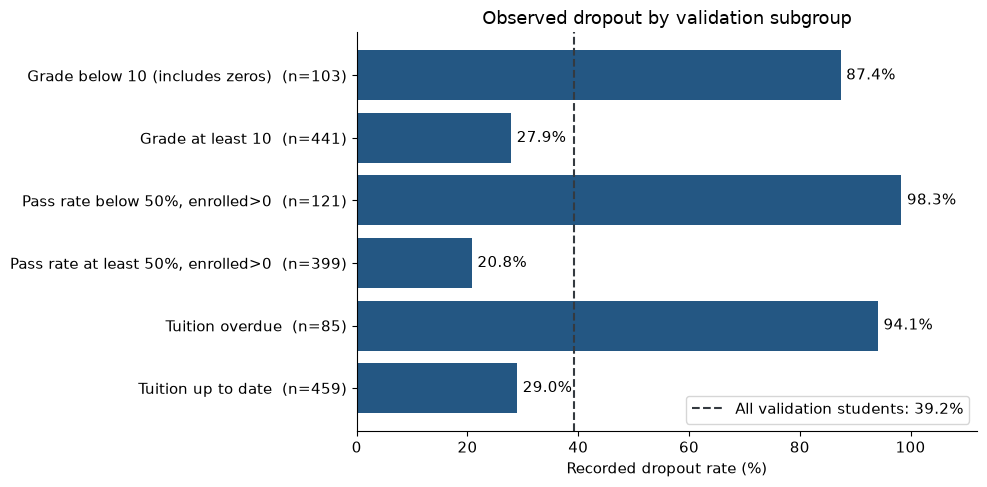

In [9]:
selected_names = [
    "Grade below 10 (includes zeros)", "Grade at least 10",
    "Pass rate below 50%, enrolled>0", "Pass rate at least 50%, enrolled>0",
    "Tuition overdue", "Tuition up to date",
]
chart_rows = OBSERVED.set_index("group").loc[selected_names]
labels = [f"{name}  (n={int(row['n'])})" for name, row in chart_rows.iterrows()]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels, chart_rows["observed_dropout_rate_pct"], color="#245783")
ax.invert_yaxis()
overall = 100 * VALIDATION["target"].mean()
ax.axvline(overall, color="#343a40", linestyle="--", label=f"All validation students: {overall:.1f}%")
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in chart_rows["observed_dropout_rate_pct"]], padding=4)
ax.set(xlim=(0, 112), xlabel="Recorded dropout rate (%)", title="Observed dropout by validation subgroup")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### 9. TabICL: load the verified pretrained checkpoint
A **checkpoint** is the model-weight file. The first download may take time; later runs use the local cache. No API key is required for this public checkpoint. Verification stays enabled. An unexpected SHA256 stops the run.

Set `RUN_TABICL=False` if you only want fast data/testing cells. To run an audit batch, the checkpoint is still required even when the separate model-teaching cells are skipped.

In [10]:
import sys
import importlib.util

print("Notebook Python:", sys.executable)
print("Package location:", importlib.util.find_spec("huggingface_hub"))

try:
    from huggingface_hub import hf_hub_download
    from huggingface_hub.errors import LocalEntryNotFoundError
    print("Imports OK")
except Exception as error:
    print(type(error).__name__, str(error))

Notebook Python: c:\Users\NOEYnoey\AppData\Local\Programs\Python\Python312\python.exe
Package location: ModuleSpec(name='huggingface_hub', loader=<_frozen_importlib_external.SourceFileLoader object at 0x00000209406CC7D0>, origin='c:\\Users\\NOEYnoey\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\huggingface_hub\\__init__.py', submodule_search_locations=['c:\\Users\\NOEYnoey\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\huggingface_hub'])
Imports OK


In [11]:
from pathlib import Path
from urllib.request import urlopen
import shutil

VERIFIED_CHECKPOINT = None

if RUN_TABICL or AUDIT_MODE != "preview":
    model_folder = Path.home() / "tabicl_model"
    model_folder.mkdir(parents=True, exist_ok=True)

    model_file = model_folder / audit.CHECKPOINT_NAME

    if not model_file.is_file():
        temporary_file = model_file.with_suffix(".ckpt.part")
        url = (
            "https://huggingface.co/jingang/TabICL/resolve/main/"
            + audit.CHECKPOINT_NAME
        )

        print("Downloading model:", model_file, flush=True)

        with urlopen(url, timeout=120) as response:
            with temporary_file.open("wb") as output:
                shutil.copyfileobj(response, output)

        audit.verified_checkpoint(temporary_file)
        temporary_file.replace(model_file)

    VERIFIED_CHECKPOINT, checkpoint_sha = audit.verified_checkpoint(model_file)
    CHECKPOINT_FILE = str(VERIFIED_CHECKPOINT)

    print("Model ready:", VERIFIED_CHECKPOINT)
    print("SHA256:", checkpoint_sha)
else:
    print("Model loading skipped.")

Model ready: C:\Users\NOEYnoey\tabicl_model\tabicl-classifier-v2-20260212.ckpt
SHA256: bdc7dbd5e4ff21f8f0456fcf90c6b7cdf72dbea960f2d05b19bec19f9b3d4ed0


### 10. TabICL: fit using training rows only
This is the actual model setup, not a mock. `n_estimators=4` is the recorded ensemble setting. The checkpoint and original training partition stay fixed. This cell does not tune parameters using validation outcomes and does not load the team's original private fitted-model bundle.

In [12]:
MODEL = None
VALIDATION_PROBABILITIES = None
if RUN_TABICL:
    import torch
    from src.modeling import build_tfm, prepare_tfm_frame
    torch.set_num_threads(4)
    X_TRAIN = prepare_tfm_frame(TRAIN, FEATURE_COLUMNS)
    X_VALIDATION = prepare_tfm_frame(VALIDATION, FEATURE_COLUMNS)
    MODEL = build_tfm(PROTOCOL["model"]["name"], FEATURE_COLUMNS,
                      n_estimators=PROTOCOL["model"]["n_estimators"])
    MODEL.set_params(model_path=str(VERIFIED_CHECKPOINT), allow_auto_download=False)
    started = time.monotonic()
    MODEL.fit(X_TRAIN, TRAIN["target"])
    if not np.array_equal(MODEL.classes_, [0, 1]):
        raise ValueError("Unexpected class order: expected Graduate=0, Dropout=1.")
    print(f"Training context fitted using {len(TRAIN):,} rows in {time.monotonic()-started:.1f} seconds.")
else:
    print("TabICL fitting skipped because RUN_TABICL=False.")

Training context fitted using 2,541 rows in 1.3 seconds.


### 11. TabICL: predict all 544 validation rows
`predict_proba()` returns two columns: Graduate probability and Dropout probability. We use column 1 for dropout risk. A probability is an estimated model score, not a guaranteed outcome.

In [13]:
if RUN_TABICL:
    started = time.monotonic()
    VALIDATION_PROBABILITIES = np.asarray(MODEL.predict_proba(X_VALIDATION))[:, 1]
    if VALIDATION_PROBABILITIES.shape != (544,) or not np.isfinite(VALIDATION_PROBABILITIES).all():
        raise ValueError("Expected 544 finite validation probabilities.")
    if np.any((VALIDATION_PROBABILITIES < 0) | (VALIDATION_PROBABILITIES > 1)):
        raise ValueError("Probabilities must be between 0 and 1.")
    print(f"Predicted all 544 validation rows in {time.monotonic()-started:.1f} seconds.")
    print("No training rows were counted as evaluation cases. No final-test rows were scored.")
    verify_lock()
else:
    print("Prediction skipped; enable RUN_TABICL to compute it.")

Predicted all 544 validation rows in 32.0 seconds.
No training rows were counted as evaluation cases. No final-test rows were scored.


### 12. Compare predictions with actual outcomes
The fixed policy flags the top **20% of the validation cohort** for outreach. This is a capacity ranking, not classification at a universal 0.5 threshold.

- **ROC-AUC:** ranking performance; higher is better.
- **Brier score:** probability error; lower is better.
- **Precision:** among flagged students, how many have recorded Dropout outcomes?
- **Recall:** among recorded Dropout outcomes, how many are flagged?

These scores assess predictions. They do not establish that explanations are faithful or that an intervention would work.

In [14]:
MODEL_RESULTS = None
if RUN_TABICL:
    MODEL_RESULTS = actual.compare_actual_outcomes(
        {"validation": VALIDATION}, {"validation": VALIDATION_PROBABILITIES},
        NOTEBOOK_OUTPUT / "actual_validation",
    )
    metrics = MODEL_RESULTS["partitions"]["validation"]
    display(pd.DataFrame([
        ["Validation rows scored", str(MODEL_RESULTS["n_rows_scored"])],
        ["ROC-AUC", f"{metrics['roc_auc']:.4f}"],
        ["Brier score", f"{metrics['brier_score']:.4f}"],
        ["Precision among outreach flags", f"{metrics['dropout_precision']:.1%}"],
        ["Recall of actual dropout cases", f"{metrics['dropout_recall']:.1%}"],
        ["Balanced accuracy under capacity policy", f"{metrics['balanced_accuracy']:.1%}"],
    ], columns=["Metric", "This notebook run"]))
    audit.atomic_json(NOTEBOOK_OUTPUT / "model_provenance.json", {
        "origin": "refit_from_recorded_settings", "original_saved_team_model_loaded": False,
        "training_rows": len(TRAIN), "validation_rows": len(VALIDATION),
        "checkpoint_sha256": checkpoint_sha, "test_evaluated": False,
        "source_signatures": SOURCE_SIGNATURES,
    })
else:
    print("No live model metrics calculated in this run.")

,Metric,This notebook run
0,Validation rows scored,544
1,ROC-AUC,0.9521
2,Brier score,0.0708
3,Precision among outreach flags,100.0%
4,Recall of actual dropout cases,50.7%
5,Balanced accuracy under capacity policy,75.4%


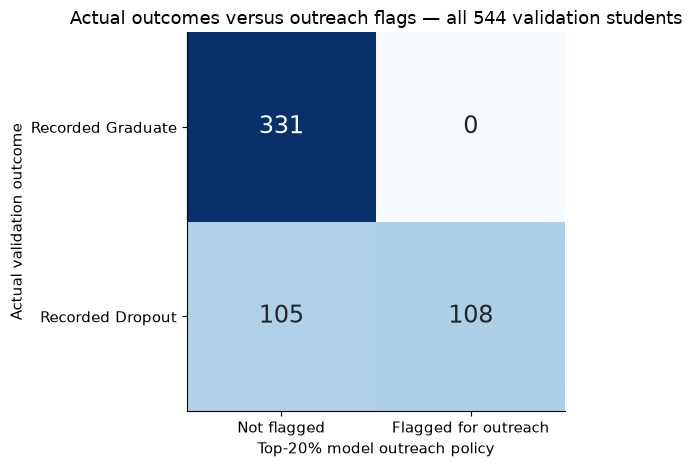

**This run:** 108 students were flagged; 108 have recorded Dropout outcomes and 0 have recorded Graduate outcomes. **105 of 213 dropout cases were left unflagged.** 

In [22]:
if MODEL_RESULTS is not None:
    matrix = np.array(metrics["confusion_matrix"], dtype=int)
    fig, ax = plt.subplots(figsize=(7, 4.8))
    ax.imshow(matrix, cmap="Blues", vmin=0)
    for (row, col), count in np.ndenumerate(matrix):
        ax.text(col, row, str(count), ha="center", va="center", fontsize=17,
                color="white" if count > matrix.max()/2 else "#20262b")
    ax.set(xticks=[0, 1], xticklabels=["Not flagged", "Flagged for outreach"],
           yticks=[0, 1], yticklabels=["Recorded Graduate", "Recorded Dropout"],
           xlabel="Top-20% model outreach policy", ylabel="Actual validation outcome",
           title="Actual outcomes versus outreach flags — all 544 validation students")
    fig.tight_layout()
    plt.show()
    tn, fp, fn, tp = matrix.ravel()
    display(Markdown(
        f"**This run:** {tp+fp} students were flagged; {tp} have recorded Dropout outcomes "
        f"and {fp} have recorded Graduate outcomes. **{fn} of {tp+fn} dropout cases were left unflagged.** "
    ))

### 13. Check genuine explanation-audit progress
Data checks, prediction evaluation and explanation cases are different stages. An audit is complete only when all **544 distinct original validation IDs** have complete evidence and the report checks pass.

Existing case files remain in `W1_Noey_Enhanced/outputs/cases`. Notebook model-teaching outputs are stored separately under `outputs/notebook`; they do not replace or rewrite the recorded case manifest.

In [16]:
def audit_status():
    manifest_file = OUTPUTS / "cases/manifest.json"
    records = audit.load_cases(OUTPUTS / "cases")
    valid_ids = set(VALIDATION["source_row_id"].astype(int))
    saved_ids = {row["source_row_id"] for row in records}
    if not saved_ids.issubset(valid_ids):
        raise ValueError("A saved case is outside the original validation population.")
    manifest = json.loads(manifest_file.read_text()) if manifest_file.exists() else None
    source_matches = manifest is None or (
        manifest.get("hashes") == SOURCE_SIGNATURES and manifest.get("version") == audit.SCRIPT_VERSION
    )
    return {"Saved complete case files": len(records), "Required validation cases": 544,
            "Original source/protocol hashes match": source_matches,
            "All validation IDs covered": saved_ids == valid_ids,
            "Full report ready": saved_ids == valid_ids and source_matches}, records

status, SAVED_CASES = audit_status()
display(pd.DataFrame([status]).T.rename(columns={0: "Status"}))
if not status["Original source/protocol hashes match"]:
    display(Markdown("**Stop before resuming:** saved cases belong to different source/protocol versions. Preserve the files and reconcile their provenance; do not delete the manifest to bypass the check."))

,Status
Saved complete case files,0
Required validation cases,544
Original source/protocol hashes match,True
All validation IDs covered,False
Full report ready,False


### 14. Run one new case or the full audit
To test execution, change **`AUDIT_MODE="one_case"`** in the configuration cell and rerun it, then run this cell. For the full audit choose **`AUDIT_MODE="full"`**. The full option has **no case cap** and skips compatible completed cases.

The audit includes local SHAP, ranked/random deletion, 10 selected-group pair probes, six OLS/Ridge/Lasso surrogates, seed/background/grade-perturbation stability, and configured support scenarios. The supported inference cache is checked against uncached validation and masked-probe outputs; small bounded numerical differences and exact outreach-flag agreement are recorded.

This cell stays busy while the child process runs. It updates a short live log and saved-file count. **Interrupt the notebook kernel to stop the current task.** Saved complete cases remain resumable; the unfinished case may need to rerun. Closing the notebook or stopping its environment can interrupt the job. Do not launch a duplicate audit in another notebook.

In [17]:
import threading, queue, collections, html, re

def find_running_audits():
    import psutil
    found = []
    for process in psutil.process_iter(["pid", "cmdline"]):
        try:
            command = process.info["cmdline"] or []
            if "--run" in command and any("run_enhanced_audit.py" in arg for arg in command):
                if Path(process.cwd()).resolve() == CODE_ROOT:
                    found.append(process.info["pid"])
        except (psutil.NoSuchProcess, psutil.AccessDenied):
            continue
    return found

def run_project_script(script_name, arguments):
    log_dir = NOTEBOOK_OUTPUT / "logs"
    log_dir.mkdir(exist_ok=True)
    log_file = log_dir / f"{Path(script_name).stem}_{time.time_ns()}.log"
    command = [sys.executable, "-u", str(AUDIT_ROOT / "scripts" / script_name), *arguments]
    lines = queue.Queue()
    recent = collections.deque(maxlen=12)
    started = time.monotonic()
    process = subprocess.Popen(command, cwd=CODE_ROOT, env=os.environ.copy(),
                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, bufsize=1)
    def read_output():
        for line in process.stdout:
            lines.put(line)
        process.stdout.close()
    threading.Thread(target=read_output, daemon=True).start()
    panel = display(HTML("<p>Starting the project task…</p>"), display_id=True)
    updated = 0.0
    try:
        with log_file.open("w", encoding="utf-8") as log:
            while process.poll() is None or not lines.empty():
                try:
                    line = lines.get(timeout=1)
                    log.write(line)
                    log.flush()
                    recent.append(re.sub(r"(https?://[^\s?]+)\?\S+", r"\1?[parameters omitted]", line).rstrip())
                except queue.Empty:
                    pass
                if time.monotonic() - updated >= 2:
                    saved = len(list((OUTPUTS / "cases").glob("case_*.json")))
                    panel.update(HTML(
                        f"<p><b>Saved case files: {saved}/544</b> · elapsed {time.monotonic()-started:.0f}s</p>"
                        + "<pre>" + html.escape("\n".join(recent)) + "</pre>"))
                    updated = time.monotonic()
    except KeyboardInterrupt:
        process.terminate()
        try:
            process.wait(timeout=15)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait(timeout=15)
        panel.update(HTML("<p>Task stopped. Complete case files were retained. Resume using the same mode and inputs.</p>"))
        raise
    finally:
        verify_lock()
    panel.update(HTML("<pre>" + html.escape("\n".join(recent)) + "</pre>"))
    print("Full task log:", log_file)
    if process.returncode:
        raise RuntimeError(f"Project task exited with code {process.returncode}. Read the log above; do not remove safeguards to continue.")
    print(f"Task completed in {time.monotonic()-started:.1f} seconds.")

if AUDIT_MODE == "preview":
    print('Preview mode: no new explanation cases computed. Choose "one_case" or "full" when ready.')
else:
    status, _ = audit_status()
    if not status["Original source/protocol hashes match"]:
        raise RuntimeError("Saved source/protocol hashes differ. Preserve and reconcile the earlier run.")
    active = find_running_audits()
    if active:
        raise RuntimeError(f"An audit is already running in this project (PID {active}). Do not start a duplicate.")
    if VERIFIED_CHECKPOINT is None:
        raise RuntimeError("Run the checkpoint cell under step 9 after changing AUDIT_MODE.")
    arguments = ["--run", "--inference-cache", "--checkpoint", str(VERIFIED_CHECKPOINT)]
    if AUDIT_MODE == "one_case":
        arguments += ["--max-new-cases", "1"]
    run_project_script("run_enhanced_audit.py", arguments)
    status, SAVED_CASES = audit_status()
    display(pd.DataFrame([status]).T.rename(columns={0: "Status"}))

Preview mode: no new explanation cases computed. Choose "one_case" or "full" when ready.


### 15. Read one saved SHAP/pair/surrogate case — optional
Set `SHOW_SAVED_CASE=True` in the configuration cell to view the first saved case. Positive grouped SHAP raises the model score relative to its training background; negative SHAP lowers it. This is not evidence of causation.

The six surrogate variants mimic TabICL on held-out **feature-mask patterns**. Their MAE is not student-dropout accuracy. A single case cannot establish population-level explanation quality. Keep notebooks containing case-level outputs in restricted storage.

In [18]:
if SHOW_SAVED_CASE:
    _, SAVED_CASES = audit_status()
    if not SAVED_CASES:
        print('No genuine saved case yet. Use AUDIT_MODE="one_case" first.')
    else:
        example = SAVED_CASES[0]
        display(Markdown("**One genuine saved case only — not a full-cohort conclusion.**"))
        display(pd.DataFrame(example["baseline_group_contributions"])[["feature_group", "signed_shap", "absolute_group_shap"]])
        display(pd.DataFrame(example["surrogate_comparison"]["summary"])[
            ["variant", "holdout_mae", "holdout_rmse", "nonzero_terms", "fraction_outside_probability_range"]
        ].sort_values("holdout_mae"))
        display(pd.DataFrame(example["stability"])[["variation", "valid_runs", "top_5_overlap", "status"]])
else:
    print("Case-level display is off. Set SHOW_SAVED_CASE=True to inspect a saved example locally.")

Case-level display is off. Set SHOW_SAVED_CASE=True to inspect a saved example locally.


### 16. Real-model student scenarios — optional
Set `RUN_STUDENT_SCENARIOS=True`, choose `STUDENT_INDEX` between 0 and 543, and run this cell after the TabICL cells. It scores the existing validated scenario definitions and recomputes the cohort rank with other scores held fixed.

**Historical grade/credit edits are retrospective sensitivity, not feasible post-semester recourse.** Tuition/debt resolutions require administrative feasibility checks. Changed model risk is not a measured real-world intervention effect.

In [19]:
if RUN_STUDENT_SCENARIOS:
    if MODEL is None or VALIDATION_PROBABILITIES is None:
        raise RuntimeError("Enable RUN_TABICL and run the model cells first.")
    if not isinstance(STUDENT_INDEX, int) or not 0 <= STUDENT_INDEX < len(VALIDATION):
        raise ValueError("STUDENT_INDEX must be a validation position from 0 to 543.")
    from student_improvement_simulation import proposal_scenarios
    from src.explanations import recompute_first_semester_features
    from src.modeling import capacity_predictions, prepare_tfm_frame
    scenarios = proposal_scenarios(X_VALIDATION.iloc[STUDENT_INDEX], recompute_first_semester_features)
    changed_rows = pd.DataFrame([row for _, row, _ in scenarios])
    changed_probabilities = np.asarray(MODEL.predict_proba(prepare_tfm_frame(changed_rows, FEATURE_COLUMNS)))[:, 1]
    scenario_table = []
    baseline = float(VALIDATION_PROBABILITIES[STUDENT_INDEX])
    for (name, _, kind), value in zip(scenarios, changed_probabilities):
        if name == "Original profile":
            value = baseline
        changed_cohort = VALIDATION_PROBABILITIES.copy()
        changed_cohort[STUDENT_INDEX] = value
        flags, _ = capacity_predictions(changed_cohort)
        ordering = np.lexsort((np.arange(len(changed_cohort)), -changed_cohort))
        scenario_table.append({"Scenario": name, "Model risk (%)": 100*value,
                               "Change (percentage points)": 100*(value-baseline),
                               "Flagged after": bool(flags[STUDENT_INDEX]),
                               "Cohort rank after": int(np.flatnonzero(ordering==STUDENT_INDEX)[0]+1),
                               "Interpretation": kind})
    display(pd.DataFrame(scenario_table).round(3))
    verify_lock()
else:
    print("Scenario computation is off. Enable RUN_STUDENT_SCENARIOS to run a real-model sensitivity example.")

Scenario computation is off. Enable RUN_STUDENT_SCENARIOS to run a real-model sensitivity example.


### 17. Generate and read a report
`REPORT_MODE="auto"` generates the full report **only after 544/544 cases**. If you explicitly choose `REPORT_MODE="partial"`, a preview is labelled incomplete. Partial evidence is not a completed full audit.

In [20]:
status, SAVED_CASES = audit_status()
REPORT_FILE = None
if REPORT_MODE == "none":
    print("Report generation is off.")
elif status["Full report ready"]:
    run_project_script("run_enhanced_audit.py", ["--report"])
    REPORT_FILE = OUTPUTS / "tables/W1_COMPLETE_REPORT.md"
elif REPORT_MODE == "partial" and SAVED_CASES:
    if not status["Original source/protocol hashes match"]:
        raise RuntimeError("Source/protocol mismatch: do not generate a mixed-version preview.")
    run_project_script("run_enhanced_audit.py", ["--report-partial"])
    REPORT_FILE = OUTPUTS / "tables/W1_PARTIAL_PREVIEW.md"
else:
    print(f"{status['Saved complete case files']}/544 case files saved. Full report not generated; finish the remaining cases first.")
if REPORT_FILE is not None:
    display(Markdown(REPORT_FILE.read_text()))
    for figure in sorted((OUTPUTS / "figures").glob("*.png")):
        display(Image(filename=str(figure)))

0/544 case files saved. Full report not generated; finish the remaining cases first.


## Checks
The status below comes from files and computations in this run. Please refer to the saved audit in separate file (run on cloud)

In [26]:
import os, sys, time, subprocess, collections, html
from IPython.display import display, HTML

def run_project_script(script_name, arguments):
    log_dir = NOTEBOOK_OUTPUT / "logs"
    log_dir.mkdir(parents=True, exist_ok=True)
    log_path = log_dir / f"audit_{time.time_ns()}.log"

    command = [
        sys.executable, "-u",
        str(AUDIT_ROOT / "scripts" / script_name),
        *arguments,
    ]

    environment = {
        **os.environ,
        "PYTHONIOENCODING": "utf-8",
        "PYTHONUTF8": "1",
    }

    recent = collections.deque(maxlen=12)
    started = time.monotonic()
    panel = display(HTML("<p>Starting audit...</p>"), display_id=True)

    # Direct file logging avoids the failed reader thread.
    with log_path.open("wb") as writer:
        process = subprocess.Popen(
            command,
            cwd=CODE_ROOT,
            env=environment,
            stdout=writer,
            stderr=subprocess.STDOUT,
        )

        try:
            with log_path.open(
                "r", encoding="utf-8", errors="replace"
            ) as reader:
                while True:
                    recent.extend(reader.read().splitlines())
                    finished = process.poll() is not None

                    if finished:
                        recent.extend(reader.read().splitlines())

                    count = len(list(
                        (OUTPUTS / "cases").glob("case_*.json")
                    ))

                    panel.update(HTML(
                        f"<p><b>Saved cases: {count}/544</b> · "
                        f"elapsed {time.monotonic()-started:.0f}s</p>"
                        + "<pre>"
                        + html.escape("\n".join(recent))
                        + "</pre>"
                    ))

                    if finished:
                        break

                    time.sleep(2)

        except KeyboardInterrupt:
            process.terminate()
            try:
                process.wait(timeout=15)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait(timeout=15)
            print("Stopped. Saved cases were retained.")
            raise

        finally:
            verify_lock()

    print("Log file:", log_path)

    if process.returncode != 0:
        raise RuntimeError(
            f"Audit exited with code {process.returncode}. "
            "Check the log above."
        )


AUDIT_MODE = "full"
REPORT_MODE = "auto"

active_jobs = find_running_audits()

if active_jobs:
    print("An audit is already running. Process IDs:", active_jobs)
else:
    if VERIFIED_CHECKPOINT is None:
        raise RuntimeError("Run the checkpoint-loading cell first.")

    print("Starting/resuming ALL 544 validation cases...", flush=True)

    run_project_script(
        "run_enhanced_audit.py",
        [
            "--run",
            "--inference-cache",
            "--checkpoint",
            str(VERIFIED_CHECKPOINT),
        ],
    )

    status, _ = audit_status()
    display(pd.DataFrame([status]).T)

KeyboardInterrupt: 